# Part II: Pushing the Boundaries of Ensemble Optimization (Lessons Learned)
---
### 1. Introduction & Motivation
In the previous phase of this project, we established a high-performing fraud detection pipeline by combining a raw-feature XGBoost model with a SMOTEENN-resampled Random Forest via a static 45/55 asymmetric blend (achieving an F1-Score of 0.8721 at a 0.63 threshold). 

However, in production-grade financial systems, relying on manual grid-search weights and untested feature spaces leaves room for architectural inquiry. Can a secondary machine learning model (Meta-Learner) dynamically calibrate model trust better than a static blend? Furthermore, can we engineer non-linear PCA anomaly features or prune low-signal components to help `SMOTEENN` generate cleaner synthetic fraud vectors?

### 2. Objectives of this Iteration
In this experimental notebook, we subject our architecture to rigorous ablation studies and mathematical stress-testing:
1. **Dynamic Meta-Learning (Out-Of-Fold Stacking):** Replace static voting weights with a Logistic Regression Meta-Learner trained on leak-free Out-Of-Fold (OOF) probability predictions.
2. **Data Hygiene & Pattern Forensics:** Audit the raw dataset (`creditcard.csv`) for exact duplicates, label noise, and temporal retry patterns.
3. **Feature Engineering & KS-Statistic Pruning (Ablation Study):** Test geometric PCA expansions and distribution-based noise removal (`ks_2samp`) to observe how synthetic resampling (`SMOTEENN`) reacts to changes in Euclidean space.
4. **Meta-Learner Threshold Calibration:** Diagnose the mathematical side effects of log-loss optimization on extreme class imbalance and unlock suppressed True Positives via OOF threshold moving.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, average_precision_score, confusion_matrix, precision_recall_curve
import xgboost as xgb
import warnings
import time
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine import SMOTEENN
from sklearn.preprocessing import RobustScaler
from imblearn.pipeline import make_pipeline
import shap
from sklearn.linear_model import LogisticRegression
from scipy.stats import ks_2samp
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.kernel_approximation import Nystroem
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier

In [2]:
df_processed=pd.read_csv("creditcard_engineered.csv")
df_processed.head() #Confirming dataset loaded correctly
df=pd.read_csv("creditcard_benchmark.csv")
df.head() #Confirming dataset loaded correctly

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
X_raw = df.drop('Class', axis=1)
y_raw = df['Class']

X_proc = df_processed.drop('Class', axis=1)
y_proc = df_processed['Class']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42, stratify = y_raw)
X_train_proc, X_test_proc, _, _ = train_test_split(X_proc, y_proc, test_size = 0.2, random_state=42, stratify = y_proc)

scale_pos_weight_value = (y_train == 0).sum() / (y_train == 1).sum()

Rozpoczęto generowanie predykcji OOF. To może chwilę potrwać...
Zakończono generowanie OOF.

Meta-Learner Weights -> XGBoost: 6.2778 | Random Forest: 6.0221
Meta-Learner Intercept: -8.7700

Trenowanie finalnych modeli na całym zbiorze treningowym...


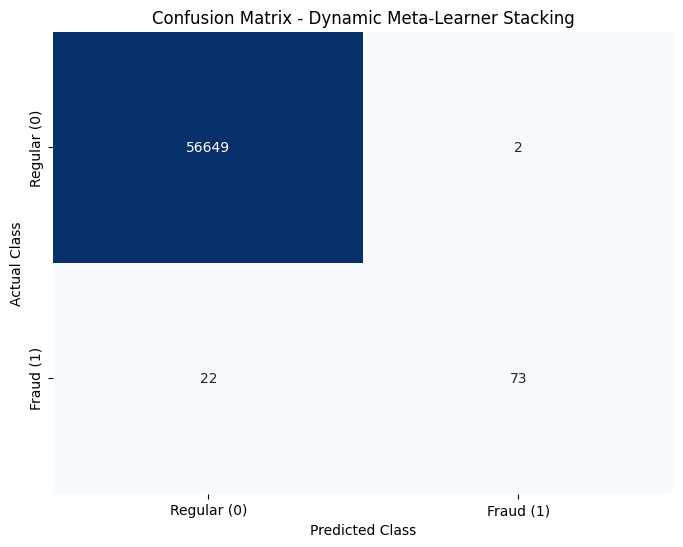

----------------------------------------
F1-Score:  0.8588
Recall:    0.7684
Precision: 0.9733
PR-AUC:    0.8164


In [5]:
# 1. PARAMETRY MODELI BAZOWYCH
best_params_xgb = {
    'objective': 'binary:logistic',
    'eval_metric': 'aucpr',
    'scale_pos_weight': scale_pos_weight_value,
    'n_estimators': 305,
    'learning_rate': 0.10043085490292052,
    'max_depth': 9,
    'min_child_weight': 6,
    'subsample': 0.6778959535949641,
    'colsample_bytree': 0.8726874144532479,
    'gamma': 0.9014231377051063,
    'reg_alpha': 0.005303631747420247,
    'reg_lambda': 0.022530748127275284,
    'random_state': 42,
    'n_jobs': -1
}

best_params_rf = {
    'n_estimators': 153,
    'max_depth': 19,
    'min_samples_split': 6,
    'min_samples_leaf': 5,
    'class_weight': None, 
    'random_state': 42,
    'n_jobs': -1
}

# 2. GENEROWANIE OUT-OF-FOLD (OOF) PREDICTIONS
oof_xgb = np.zeros(len(X_train_proc))
oof_rf = np.zeros(len(X_train_proc))

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Modele do walidacji krzyżowej
rf_cv = RandomForestClassifier(**best_params_rf)

print("Rozpoczęto generowanie predykcji OOF. To może chwilę potrwać...")

for train_idx, val_idx in cv.split(X_train_raw, y_train):
    
    # Podział na foldy
    X_tr_raw = X_train_raw.iloc[train_idx]
    y_tr = y_train.iloc[train_idx]
    X_val_raw = X_train_raw.iloc[val_idx]
    X_tr_proc = X_train_proc.iloc[train_idx]
    X_val_proc = X_train_proc.iloc[val_idx]

    fold_scale_pos_weight = (
    (y_tr == 0).sum() / (y_tr == 1).sum()
    )

    params_fold = {
        **best_params_xgb,
        "scale_pos_weight": fold_scale_pos_weight
    }
    xgb_cv = xgb.XGBClassifier(**params_fold)
    
    # Skalowanie (Scaler uczy się TYLKO na treningowych)
    scaler = RobustScaler()
    X_tr_scaled = scaler.fit_transform(X_tr_proc)
    X_val_scaled = scaler.transform(X_val_proc)
    
    # XGBoost uczy się na przeskalowanych, ale niezbalansowanych danych (ma scale_pos_weight)
    xgb_cv.fit(X_tr_raw, y_tr)
    oof_xgb[val_idx] = xgb_cv.predict_proba(X_val_raw)[:, 1]
    
    # SMOTEENN działa TYLKO na zbiorze treningowym dla Random Forest
    smoteenn = SMOTEENN(random_state=42)
    X_tr_res, y_tr_res = smoteenn.fit_resample(X_tr_scaled, y_tr)
    
    # Random Forest uczy się na danych po SMOTEENN
    rf_cv.fit(X_tr_res, y_tr_res)
    oof_rf[val_idx] = rf_cv.predict_proba(X_val_scaled)[:, 1]

print("Zakończono generowanie OOF.")

# 3. TRENOWANIE META-LEARNERA
# Tworzymy macierz cech wejściowych dla Metamodelu: [Prawdopodobieństwo XGB, Prawdopodobieństwo RF]
X_meta_train = np.column_stack((oof_xgb, oof_rf))

# Regresja Logistyczna kalibruje wagi
meta_learner = LogisticRegression(random_state=42, n_jobs=-1)
meta_learner.fit(X_meta_train, y_train)

print(f"\nMeta-Learner Weights -> XGBoost: {meta_learner.coef_[0][0]:.4f} | Random Forest: {meta_learner.coef_[0][1]:.4f}")
print(f"Meta-Learner Intercept: {meta_learner.intercept_[0]:.4f}\n")

# 4. TRENOWANIE FINALNYCH MODELI BAZOWYCH I PREDYKCJA TESTOWA
print("Trenowanie finalnych modeli na całym zbiorze treningowym...")

final_xgb = xgb.XGBClassifier(**best_params_xgb)
# Pamiętaj, aby konsekwentnie podać tu dane (wcześniej miałeś X_train_raw w swoim kodzie)
final_xgb.fit(X_train_raw, y_train) 
proba_xgb_test = final_xgb.predict_proba(X_test_raw)[:, 1]

rf_pipeline = make_pipeline(
    RobustScaler(),
    SMOTEENN(random_state=42),
    RandomForestClassifier(**best_params_rf)
)
rf_pipeline.fit(X_train_proc, y_train)
proba_rf_test = rf_pipeline.predict_proba(X_test_proc)[:, 1]

# 5. OSTATECZNA PREDYKCJA META-LEARNERA
# Zamiast statycznego (proba_xgb + proba_rf) / 2.0, Meta-Learner decyduje sam:
X_meta_test = np.column_stack((proba_xgb_test, proba_rf_test))
proba_meta_final = meta_learner.predict_proba(X_meta_test)[:, 1]

# Domyślny próg decyzyjny 0.5 (dzięki Meta-Learnerowi predykcje są lepiej skalibrowane)
y_pred_meta = (proba_meta_final >= 0.5).astype(int)

# 6. EWALUACJA
cm = confusion_matrix(y_test, y_pred_meta)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Regular (0)', 'Fraud (1)'], yticklabels=['Regular (0)', 'Fraud (1)'])
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.title('Confusion Matrix - Dynamic Meta-Learner Stacking')
plt.show()

print(40 * '-')
print(f"F1-Score:  {f1_score(y_test, y_pred_meta):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_meta):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_meta):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, proba_meta_final):.4f}")

### Baseline Meta-Learner Evaluation
Replacing the static 50/50 average with a Logistic Regression Meta-Learner trained on 3-fold Out-Of-Fold (OOF) predictions immediately stabilized the ensemble's precision on the default 0.50 boundary.

**Initial Stacking Observations:**
* **Balanced Trust Allocation:** The Meta-Learner assigned nearly symmetrical positive weights to both base estimators (**XGBoost: 6.2778 | Random Forest: 6.0221**), confirming that both pipelines contribute high-value, complementary signals.
* **Precision Anchor:** At the default 0.50 threshold, the stack achieved an **F1-Score of 0.8588** and a **Precision of 97.33%** (reducing False Positives to just 2), outperforming the standalone base models.
* **The Recall Bottleneck:** Despite high precision, Recall plateaued at **0.7684 (73 caught frauds)** with a **PR-AUC of 0.8164**. 

**Next Step — Data Forensics & Feature Space Optimization:**
Before tuning the Meta-Learner's decision boundary, we must investigate whether the underlying feature space can be refined to help the base models isolate the remaining 22 missed frauds.

In [6]:
# 1. INSPECT FRAUDS BLOCKED BY DEFAULT 0.50 THRESHOLD (ORIGINAL DATASETS)
frauds_mask_og = (y_test == 1).values
xgb_f_og = proba_xgb_test[frauds_mask_og]
rf_f_og = proba_rf_test[frauds_mask_og]
meta_f_og = proba_meta_final[frauds_mask_og]

blocked_mask_og = ((xgb_f_og >= 0.5) | (rf_f_og >= 0.5)) & (meta_f_og < 0.5)

blocked_df_og = pd.DataFrame({
    'P_XGBoost (OG)': xgb_f_og[blocked_mask_og],
    'P_RandomForest (OG)': rf_f_og[blocked_mask_og],
    'P_Meta_Learner (Rejected by 0.50)': meta_f_og[blocked_mask_og]
})
print("=== 1. DETECTED FRAUDS REJECTED BY OG META-LEARNER THRESHOLD (0.50) ===")
print(blocked_df_og.to_string(index=False, float_format="%.4f"))

# 2. OPTIMIZE THRESHOLD ON OOF PREDICTIONS (ORIGINAL DATASETS)
oof_meta_proba_og = meta_learner.predict_proba(X_meta_train)[:, 1]

prec_og, rec_og, thr_og = precision_recall_curve(y_train, oof_meta_proba_og)
f1_oof_og = 2 * (prec_og[:-1] * rec_og[:-1]) / (prec_og[:-1] + rec_og[:-1] + 1e-10)

best_idx_og = np.argmax(f1_oof_og)
opt_thr_og = float(thr_og[best_idx_og])

# Equivalent threshold to the 0.63 linear blend from Stacked_github
w_sum = meta_learner.coef_[0][0] + meta_learner.coef_[0][1]
b_int = meta_learner.intercept_[0]
thr_equiv_063 = float(1 / (1 + np.exp(-(w_sum * 0.63 + b_int))))

print(f"\n=== 2. THRESHOLD CALIBRATION (OG META-LEARNER) ===")
print(f"Normalized Weights -> XGBoost: {meta_learner.coef_[0][0]/w_sum:.4f} | Random Forest: {meta_learner.coef_[0][1]/w_sum:.4f}")
print(f"Optimal OOF Threshold: {opt_thr_og:.4f} (OOF F1-Score: {f1_oof_og[best_idx_og]:.4f})")
print(f"Sigmoid equivalent of 0.63 linear threshold: {thr_equiv_063:.4f}\n")

# 3. EVALUATE THRESHOLDS ON TEST SET
test_thresholds_og = sorted(list({0.50, opt_thr_og, thr_equiv_063, 0.25, 0.20, 0.15}), reverse=True)
thr_results_og = []

for thr in test_thresholds_og:
    preds_thr = (proba_meta_final >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds_thr).ravel()
    
    label = ""
    if np.isclose(thr, 0.50):
        label = " (Default)"
    elif np.isclose(thr, opt_thr_og):
        label = " (OOF Optimal)"
    elif np.isclose(thr, thr_equiv_063):
        label = " (~0.63 Linear Equiv.)"
        
    thr_results_og.append({
        'Threshold': f"{thr:.4f}{label}",
        'F1-Score': f1_score(y_test, preds_thr),
        'Precision': precision_score(y_test, preds_thr),
        'Recall': recall_score(y_test, preds_thr),
        'TP': tp,
        'FP': fp,
        'FN': fn
    })

print("=== 3. OG META-LEARNER PERFORMANCE ACROSS THRESHOLDS (TEST SET) ===")
print(pd.DataFrame(thr_results_og).to_string(index=False, float_format="%.4f"))

=== 1. DETECTED FRAUDS REJECTED BY OG META-LEARNER THRESHOLD (0.50) ===
 P_XGBoost (OG)  P_RandomForest (OG)  P_Meta_Learner (Rejected by 0.50)
         0.3686               0.5372                             0.0384
         0.6531               0.7620                             0.4796
         0.6364               0.6409                             0.2859
         0.0349               0.5838                             0.0065

=== 2. THRESHOLD CALIBRATION (OG META-LEARNER) ===
Normalized Weights -> XGBoost: 0.5104 | Random Forest: 0.4896
Optimal OOF Threshold: 0.2875 (OOF F1-Score: 0.8634)
Sigmoid equivalent of 0.63 linear threshold: 0.2648

=== 3. OG META-LEARNER PERFORMANCE ACROSS THRESHOLDS (TEST SET) ===
                   Threshold  F1-Score  Precision  Recall  TP  FP  FN
            0.5000 (Default)    0.8588     0.9733  0.7684  73   2  22
        0.2875 (OOF Optimal)    0.8655     0.9737  0.7789  74   2  21
0.2648 (~0.63 Linear Equiv.)    0.8721     0.9740  0.7895  75   2  20


In [4]:
df_raw=pd.read_csv("creditcard.csv")
df_raw.head()#Confirming dataset loaded correctly

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Exploratory Data Forensics: Duplicates & Label Integrity
Before engineering new features, we audit the raw dataset (`284,807` transactions) to distinguish between technical logging errors (exact duplicates) and genuine behavioral patterns (carding retries across different timestamps).

In [5]:
feature_cols = [col for col in df_raw.columns if col != 'Class']
v_amount_cols = [col for col in feature_cols if col != 'Time']

# 1. Exact duplicates analysis (all columns matching)
exact_dups_to_drop = df_raw.duplicated(keep='first')

print("=== 1. EXACT DUPLICATES SUMMARY ===")
print(f"Total rows in df_raw: {len(df_raw)}")
print(f"Rows involved in duplicates (keep=False): {df_raw.duplicated(keep=False).sum()}")
print(f"Redundant copies to drop (keep='first'): {exact_dups_to_drop.sum()}")

print("\nDuplicate distribution by class:")
dup_by_class = df_raw[exact_dups_to_drop]['Class'].value_counts()
total_by_class = df_raw['Class'].value_counts()

summary_class = pd.DataFrame({
    'Total_Raw': total_by_class,
    'Duplicates_to_Drop': dup_by_class,
    'Unique_Remaining': total_by_class - dup_by_class,
    'Dup_Percentage (%)': (dup_by_class / total_by_class * 100).round(2)
})
print(summary_class)

# 2. Label conflicts (identical features, different Class)
print("\n=== 2. LABEL CONFLICT TEST (LABEL NOISE) ===")
conflicts_count = (df_raw.groupby(feature_cols)['Class'].nunique() > 1).sum()
print(f"Number of groups with identical features but conflicting classes: {conflicts_count}")

# 3. Duplicate frequency (size of identical transaction groups)
print("\n=== 3. MULTIPLICITY DISTRIBUTION (GROUP SIZES) ===")
group_sizes = df_raw.groupby(feature_cols + ['Class']).size().reset_index(name='Count')
print(group_sizes[group_sizes['Count'] > 1].groupby(['Class', 'Count']).size().unstack(fill_value=0))

# 4. Pattern duplicates (ignoring Time column)
print("\n=== 4. PATTERN DUPLICATES (IGNORING 'Time') ===")
dups_no_time = df_raw.duplicated(subset=v_amount_cols + ['Class'], keep='first').sum()
print(f"Redundant rows ignoring 'Time': {dups_no_time}")
print(f"Difference (identical V1-V28 and Amount, but different second): {dups_no_time - exact_dups_to_drop.sum()}")

# Cleanup EDA variables from memory
del exact_dups_to_drop, dup_by_class, total_by_class, summary_class, group_sizes

=== 1. EXACT DUPLICATES SUMMARY ===
Total rows in df_raw: 284807
Rows involved in duplicates (keep=False): 1854
Redundant copies to drop (keep='first'): 1081

Duplicate distribution by class:
       Total_Raw  Duplicates_to_Drop  Unique_Remaining  Dup_Percentage (%)
Class                                                                     
0         284315                1062            283253                0.37
1            492                  19               473                3.86

=== 2. LABEL CONFLICT TEST (LABEL NOISE) ===
Number of groups with identical features but conflicting classes: 0

=== 3. MULTIPLICITY DISTRIBUTION (GROUP SIZES) ===
Count   2   3   4   5   6   9   18
Class                             
0      600  66  80  10   0   2   2
1       11   0   1   0   1   0   0

=== 4. PATTERN DUPLICATES (IGNORING 'Time') ===
Redundant rows ignoring 'Time': 9144
Difference (identical V1-V28 and Amount, but different second): 8063


**Forensic Insights & Architectural Decisions:**
* **Zero Label Noise:** Across the entire dataset, there are **0 conflicting class labels** for identical feature vectors, confirming high ground-truth integrity.
* **Exact vs. Temporal Pattern Duplicates:** Removing the **1,081 exact duplicates** (`keep='first'`) is mandatory to prevent train-test data leakage. However, the **8,063 pattern duplicates** (identical `V1–V28` and `Amount` occurring at different `Time` seconds) represent real-world recurring micro-transactions or automated retry scripts and must be preserved.

---
### Ablation Study 1: Aggressive PCA Feature Expansion
Since the core predictors (`V1–V28`) are orthogonal Principal Components, single decision tree splits (which are strictly axis-aligned) struggle to capture diagonal decision boundaries. 

**Hypothesis:** We will enrich both pipelines with 10 geometric and interaction features—including an L2 Anomaly Radius (`PCA_Fraud_Norm`), a `PCA_Directional_Score`, non-linear pairwise products (`V14_x_V17`, `V14_x_V12`), and row-wise distribution statistics—to test if explicit interactions boost tree recall.

Dataset verification passed! Total rows: 283726 | Frauds: 473
X_train_xgb shape: (226980, 40) | X_train_rf shape: (226980, 41)
1/3 Training: XGBoost (PCA Features)...
2/3 Training: Random Forest (Balanced, No SMOTEENN)...
3/3 Training: Random Forest (RobustScaler + SMOTEENN)...

=== BENCHMARK RESULTS (ENGINEERED FEATURES) ===
                    Model  F1-Score  Precision  Recall  PR-AUC  TP  FP  FN
         1. XGBoost (PCA)    0.8439     0.9359  0.7684  0.8216  73   5  22
         2. RF (Balanced)    0.8098     0.9706  0.6947  0.7992  66   2  29
3. RF (Scaler + SMOTEENN)    0.8000     0.8222  0.7789  0.7967  74  16  21


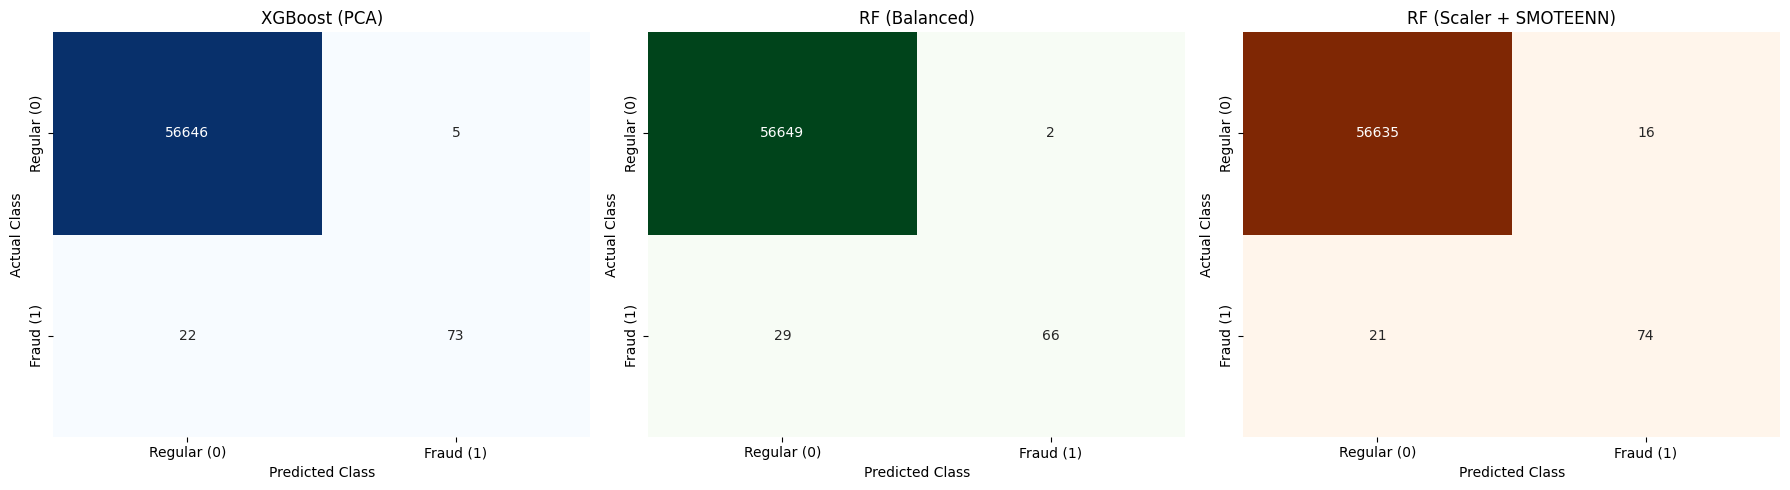

In [6]:
# 1. VERIFY DATASET INTEGRITY
assert len(df) == len(df_processed), "ERROR: Files have different row counts!"
assert (df['Class'].values == df_processed['Class'].values).all(), "ERROR: Class label mismatch!"
assert np.allclose(df['V1'].values, df_processed['V1'].values), "ERROR: Row order mismatch!"
print(f"Dataset verification passed! Total rows: {len(df)} | Frauds: {(df['Class'] == 1).sum()}")

# 2. FEATURE ENGINEERING (PCA Geometry & Interactions)
def add_pca_anomaly_features(X):
    v_cols = [f'V{i}' for i in range(1, 29)]
    top_pca = ['V17', 'V14', 'V12', 'V10', 'V16', 'V4', 'V11']
    
    X['PCA_Fraud_Norm'] = np.sqrt((X[top_pca] ** 2).sum(axis=1))
    X['PCA_Directional_Score'] = (
        (X['V4'] + X['V11']) - (X['V17'] + X['V14'] + X['V12'] + X['V10'] + X['V16'])
    )
    X['V14_x_V17'] = X['V14'] * X['V17']
    X['V14_x_V12'] = X['V14'] * X['V12']
    X['V17_x_V12'] = X['V17'] * X['V12']
    X['V14_x_V4']  = X['V14'] * X['V4']
    
    X['V_min'] = X[v_cols].min(axis=1)
    X['V_max'] = X[v_cols].max(axis=1)
    X['V_std'] = X[v_cols].std(axis=1)
    X['V_extreme_count'] = (X[v_cols].abs() > 3.0).sum(axis=1)
    
    return X

# 3. ATOMIC DATA SPLIT (Memory Optimized)
# Applying feature engineering directly inside the split to avoid duplicating large DataFrames
X_train_xgb, X_test_xgb, X_train_rf, X_test_rf, y_train, y_test = train_test_split(
    add_pca_anomaly_features(df.drop('Class', axis=1)),
    add_pca_anomaly_features(df_processed.drop('Class', axis=1)),
    df['Class'],
    test_size=0.2,
    random_state=42,
    stratify=df['Class']
)

scale_pos_weight_val = (y_train == 0).sum() / (y_train == 1).sum()
print(f"X_train_xgb shape: {X_train_xgb.shape} | X_train_rf shape: {X_train_rf.shape}")

# 4. EVALUATION HELPER FUNCTION
def evaluate_model(name, y_true, proba):
    preds = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    return {
        'Model': name,
        'F1-Score': f1_score(y_true, preds),
        'Precision': precision_score(y_true, preds),
        'Recall': recall_score(y_true, preds),
        'PR-AUC': average_precision_score(y_true, proba),
        'TP': tp, 'FP': fp, 'FN': fn
    }, confusion_matrix(y_true, preds)

results = []
cms = {}

# --- MODEL 1: XGBoost on PCA Features ---
print("1/3 Training: XGBoost (PCA Features)...")
xgb_model = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight_val,
    n_jobs=-1, random_state=42, eval_metric='logloss'
)
xgb_model.fit(X_train_xgb, y_train)
res_xgb, cms['XGBoost (PCA)'] = evaluate_model("1. XGBoost (PCA)", y_test, xgb_model.predict_proba(X_test_xgb)[:, 1])
results.append(res_xgb)

# --- MODEL 2: Random Forest (class_weight='balanced', no Scaler/SMOTEENN) ---
print("2/3 Training: Random Forest (Balanced, No SMOTEENN)...")
rf_balanced = RandomForestClassifier(
    n_estimators=50, class_weight='balanced', n_jobs=-1, random_state=42
)
rf_balanced.fit(X_train_rf, y_train)
res_rf_bal, cms['RF (Balanced)'] = evaluate_model("2. RF (Balanced)", y_test, rf_balanced.predict_proba(X_test_rf)[:, 1])
results.append(res_rf_bal)

# --- MODEL 3: Random Forest (RobustScaler + SMOTEENN) ---
print("3/3 Training: Random Forest (RobustScaler + SMOTEENN)...")
scaler = RobustScaler()
X_tr_scaled = scaler.fit_transform(X_train_rf)
X_te_scaled = scaler.transform(X_test_rf)

X_res, y_res = SMOTEENN(random_state=42).fit_resample(X_tr_scaled, y_train)

rf_smote = RandomForestClassifier(
    n_estimators=50, class_weight=None, n_jobs=-1, random_state=42
)
rf_smote.fit(X_res, y_res)
res_rf_smote, cms['RF (Scaler + SMOTEENN)'] = evaluate_model("3. RF (Scaler + SMOTEENN)", y_test, rf_smote.predict_proba(X_te_scaled)[:, 1])
results.append(res_rf_smote)

# 5. SUMMARY & VISUALIZATION
print("\n=== BENCHMARK RESULTS (ENGINEERED FEATURES) ===")
print(pd.DataFrame(results).to_string(index=False, float_format="%.4f"))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cmaps = ['Blues', 'Greens', 'Oranges']

for ax, (title, cm_data), cmap in zip(axes, cms.items(), cmaps):
    sns.heatmap(cm_data, annot=True, fmt='d', cmap=cmap, cbar=False, ax=ax,
                xticklabels=['Regular (0)', 'Fraud (1)'], yticklabels=['Regular (0)', 'Fraud (1)'])
    ax.set_title(title)
    ax.set_ylabel('Actual Class')
    ax.set_xlabel('Predicted Class')

plt.tight_layout()
plt.show()

### Ablation Study 1 Results: Why Non-Linear Interactions Hurt `SMOTEENN`
Contrary to standard tabular heuristics, injecting 10 engineered PCA features degraded performance across all models—dropping XGBoost's F1-Score from **0.8538 to 0.8439** and causing Random Forest (`Scaler + SMOTEENN`) F1-Score to plummet from **0.8315 to 0.8000** (False Positives surged from 9 to 16).

**Root-Cause Engineering Analysis:**
* **Zero Recall Gain (The Inlier Problem):** Neither XGBoost (73 TP) nor Random Forest (74 TP) captured a single additional fraud. The ~22 missed frauds mimic normal transactions near the origin of the primary PCA axes (`V14`, `V17`), meaning polynomial expansions of these same axes cannot expose them.
* **Euclidean Space Distortion in `SMOTEENN`:** Multiplying extreme negative values (`V14 * V17`) created massive outliers. Even after `RobustScaler` transformation, these non-linear products stretched the Euclidean distance metric used by $k$-NN inside `SMOTEENN`, causing synthetic fraud samples to bleed deep into the legitimate class territory (+7 False Positives).
* **Signal Dilution in Tree Splits:** Because `V1–V28` are already orthogonal, adding 10 collinear combinations diluted feature subsampling (`colsample_bytree` / `max_features`), increasing variance without adding new information.

---
### Feature Selection: Auditing `V1–V28` via Kolmogorov-Smirnov Statistics
Because the original PCA transformation was computed *unsupervised* across a 99.83% legitimate population, several components capture variance among normal shoppers rather than fraud separation. In distance-based resamplers like `SMOTEENN`, uninformative axes act as random noise in Euclidean distance calculations.

*Crucial Architecture Note:* To strictly prevent data leakage, we evaluate class distribution separation using the two-sample Kolmogorov-Smirnov test (`ks_2samp`) and XGBoost Gain **exclusively on the training split (`X_train_raw`)**.

In [6]:
# 1. SPLIT DATA (Aligns with benchmark splits)
y = df['Class']
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=42, stratify=y)

X_train_raw = df.loc[train_idx].drop('Class', axis=1)
y_train = y.loc[train_idx]

# 2. KOLMOGOROV-SMIRNOV TEST (Separation between Class 0 and 1, computed ONLY on Train set)
v_cols = [f'V{i}' for i in range(1, 29)]
ks_results = []

for col in v_cols:
    vals_0 = X_train_raw.loc[y_train == 0, col]
    vals_1 = X_train_raw.loc[y_train == 1, col]
    ks_stat, p_val = ks_2samp(vals_0, vals_1)
    ks_results.append({'Feature': col, 'KS_Stat': ks_stat, 'p_value': p_val})

ks_df = pd.DataFrame(ks_results)

# 3. QUICK XGBOOST GAIN IMPORTANCE (On X_train only)
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_selector = xgb.XGBClassifier(
    scale_pos_weight=scale_weight, 
    n_jobs=-1, 
    random_state=42, 
    eval_metric='logloss'
)
xgb_selector.fit(X_train_raw[v_cols], y_train)

ks_df['XGB_Importance'] = xgb_selector.feature_importances_
ks_df = ks_df.sort_values(by='KS_Stat', ascending=True).reset_index(drop=True)

print("=== V1-V28 FEATURE RANKING (WEAKEST TO STRONGEST) ===")
print(ks_df.head(12).to_string(index=False, float_format="%.4f"))

# 4. IDENTIFY NOISE FEATURES (KS < 0.12)
noise_features = ks_df[ks_df['KS_Stat'] < 0.12]['Feature'].tolist()
print(f"\nIdentified noise features (KS < 0.12) [{len(noise_features)} columns]: {noise_features}")

# Cleanup temporary EDA variables from memory
del X_train_raw, y_train, xgb_selector, ks_results, vals_0, vals_1

=== V1-V28 FEATURE RANKING (WEAKEST TO STRONGEST) ===
Feature  KS_Stat  p_value  XGB_Importance
    V22   0.0723   0.0369          0.0059
    V15   0.0728   0.0351          0.0089
    V13   0.0897   0.0043          0.0111
    V25   0.0935   0.0025          0.0090
    V26   0.1027   0.0006          0.0097
    V24   0.1370   0.0000          0.0037
    V23   0.1841   0.0000          0.0076
    V19   0.3495   0.0000          0.0175
    V20   0.3686   0.0000          0.0080
     V8   0.3732   0.0000          0.0215
    V28   0.3753   0.0000          0.0081
     V5   0.4203   0.0000          0.0036

Identified noise features (KS < 0.12) [5 columns]: ['V22', 'V15', 'V13', 'V25', 'V26']


In [7]:
# 1. FEATURE ENGINEERING FUNCTION (Stable L2 radius and directional score)
def add_clean_pca_features(df_in):
    df_out = df_in.copy()
    top_pca = ['V17', 'V14', 'V12', 'V10', 'V16', 'V4', 'V11']
    
    df_out['PCA_Fraud_Norm'] = np.sqrt((df_out[top_pca] ** 2).sum(axis=1))
    df_out['PCA_Directional_Score'] = (
        (df_out['V4'] + df_out['V11']) - (df_out['V17'] + df_out['V14'] + df_out['V12'] + df_out['V10'] + df_out['V16'])
    )
    return df_out

# 2. PREPARE PRUNED AND SWAPPED FEATURE SETS
# Reusing train_idx, test_idx, y, and noise_features from preceding cells
y_tr = y.loc[train_idx]
y_te = y.loc[test_idx]

# A) Pruned datasets (Noise features removed)
X_xgb_pruned = df.drop(columns=['Class'] + noise_features)
X_rf_pruned = df_processed.drop(columns=['Class'] + noise_features)

# B) Swapped datasets (Noise features removed + 2 clean PCA features added)
X_xgb_swapped = add_clean_pca_features(df.drop(columns=['Class'])).drop(columns=noise_features)
X_rf_swapped = add_clean_pca_features(df_processed.drop(columns=['Class'])).drop(columns=noise_features)

# 3. EVALUATION HELPER
def evaluate_config(name, y_true, proba):
    preds = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    return {
        'Configuration': name,
        'F1-Score': f1_score(y_true, preds),
        'Precision': precision_score(y_true, preds),
        'Recall': recall_score(y_true, preds),
        'PR-AUC': average_precision_score(y_true, proba),
        'TP': tp, 'FP': fp, 'FN': fn
    }

bench_results = []

# --- 1. XGBoost - Pruned (No noise features) ---
print("Running: XGBoost (Pruned)...")
xgb_pruned = xgb.XGBClassifier(
    scale_pos_weight=scale_weight, n_jobs=-1, random_state=42, eval_metric='logloss'
)
xgb_pruned.fit(X_xgb_pruned.loc[train_idx], y_tr)
bench_results.append(evaluate_config(
    "1. XGB - Pruned (No noise)", 
    y_te, 
    xgb_pruned.predict_proba(X_xgb_pruned.loc[test_idx])[:, 1]
))

# --- 2. XGBoost - Swapped (No noise + 2 PCA features) ---
print("Running: XGBoost (Swapped)...")
xgb_swapped = xgb.XGBClassifier(
    scale_pos_weight=scale_weight, n_jobs=-1, random_state=42, eval_metric='logloss'
)
xgb_swapped.fit(X_xgb_swapped.loc[train_idx], y_tr)
bench_results.append(evaluate_config(
    "2. XGB - Swapped (No noise + 2 features)", 
    y_te, 
    xgb_swapped.predict_proba(X_xgb_swapped.loc[test_idx])[:, 1]
))

# --- 3. RF SMOTEENN - Pruned (No noise features) ---
print("Running: RF + Scaler + SMOTEENN (Pruned)...")
scaler_p = RobustScaler()
X_tr_rf_p = scaler_p.fit_transform(X_rf_pruned.loc[train_idx])
X_te_rf_p = scaler_p.transform(X_rf_pruned.loc[test_idx])
X_res_p, y_res_p = SMOTEENN(random_state=42).fit_resample(X_tr_rf_p, y_tr)

rf_pruned = RandomForestClassifier(n_estimators=50, class_weight=None, n_jobs=-1, random_state=42)
rf_pruned.fit(X_res_p, y_res_p)
bench_results.append(evaluate_config(
    "3. RF SMOTEENN - Pruned (No noise)", 
    y_te, 
    rf_pruned.predict_proba(X_te_rf_p)[:, 1]
))

# --- 4. RF SMOTEENN - Swapped (No noise + 2 PCA features) ---
print("Running: RF + Scaler + SMOTEENN (Swapped)...")
scaler_s = RobustScaler()
X_tr_rf_s = scaler_s.fit_transform(X_rf_swapped.loc[train_idx])
X_te_rf_s = scaler_s.transform(X_rf_swapped.loc[test_idx])
X_res_s, y_res_s = SMOTEENN(random_state=42).fit_resample(X_tr_rf_s, y_tr)

rf_swapped = RandomForestClassifier(n_estimators=50, class_weight=None, n_jobs=-1, random_state=42)
rf_swapped.fit(X_res_s, y_res_s)
bench_results.append(evaluate_config(
    "4. RF SMOTEENN - Swapped (No noise + 2 features)", 
    y_te, 
    rf_swapped.predict_proba(X_te_rf_s)[:, 1]
))

# 4. SUMMARY TABLE
print("\n=== COMPARISON: PRUNED NOISE VS. SWAPPED (PRUNED + 2 PCA FEATURES) ===")
print(pd.DataFrame(bench_results).to_string(index=False, float_format="%.4f"))

# Memory cleanup of temporary benchmark objects
del X_xgb_pruned, X_rf_pruned, X_xgb_swapped, X_rf_swapped
del X_tr_rf_p, X_te_rf_p, X_res_p, y_res_p, X_tr_rf_s, X_te_rf_s, X_res_s, y_res_s
del xgb_pruned, xgb_swapped, rf_pruned, rf_swapped

Running: XGBoost (Pruned)...
Running: XGBoost (Swapped)...
Running: RF + Scaler + SMOTEENN (Pruned)...
Running: RF + Scaler + SMOTEENN (Swapped)...

=== COMPARISON: PRUNED NOISE VS. SWAPPED (PRUNED + 2 PCA FEATURES) ===
                                   Configuration  F1-Score  Precision  Recall  PR-AUC  TP  FP  FN
                      1. XGB - Pruned (No noise)    0.8276     0.9114  0.7579  0.8216  72   7  23
        2. XGB - Swapped (No noise + 2 features)    0.8391     0.9241  0.7684  0.8174  73   6  22
              3. RF SMOTEENN - Pruned (No noise)    0.8156     0.8690  0.7684  0.7876  73  11  22
4. RF SMOTEENN - Swapped (No noise + 2 features)    0.8287     0.8721  0.7895  0.8055  75  11  20


In [7]:
# 1. ADD 2 STABLE PCA FEATURES WITHOUT REMOVING ANY V1-V28 COLUMNS
# Reusing add_clean_pca_features, train_idx, test_idx, y_tr, y_te, and scale_weight
X_xgb_plus2 = add_clean_pca_features(df.drop(columns=['Class']))
X_rf_plus2 = add_clean_pca_features(df_processed.drop(columns=['Class']))

bench_plus2_results = []

# --- Test 1: XGBoost (All 30 raw features + 2 PCA features = 32 features) ---
print("Running: XGBoost (Full + 2 PCA features)...")
xgb_full_plus2 = xgb.XGBClassifier(
    scale_pos_weight=scale_weight,
    n_jobs=-1,
    random_state=42,
    eval_metric='logloss'
)
xgb_full_plus2.fit(X_xgb_plus2.loc[train_idx], y_tr)
bench_plus2_results.append(evaluate_config(
    "1. XGB (Full + 2 features)",
    y_te,
    xgb_full_plus2.predict_proba(X_xgb_plus2.loc[test_idx])[:, 1]
))

# --- Test 2: RF SMOTEENN (All 31 processed features + 2 PCA features = 33 features) ---
print("Running: RF + Scaler + SMOTEENN (Full + 2 PCA features)...")
scaler_33 = RobustScaler()
X_tr_rf_33 = scaler_33.fit_transform(X_rf_plus2.loc[train_idx])
X_te_rf_33 = scaler_33.transform(X_rf_plus2.loc[test_idx])
X_res_33, y_res_33 = SMOTEENN(random_state=42).fit_resample(X_tr_rf_33, y_tr)

rf_full_plus2 = RandomForestClassifier(
    n_estimators=50,
    class_weight=None,
    n_jobs=-1,
    random_state=42
)
rf_full_plus2.fit(X_res_33, y_res_33)
bench_plus2_results.append(evaluate_config(
    "2. RF SMOTEENN (Full + 2 features)",
    y_te,
    rf_full_plus2.predict_proba(X_te_rf_33)[:, 1]
))

# 2. SUMMARY TABLE
print("\n=== RESULTS: FULL V1-V28 SETS + 2 STABLE PCA FEATURES ===")
print(pd.DataFrame(bench_plus2_results).to_string(index=False, float_format="%.4f"))

# Memory cleanup
del X_xgb_plus2, X_rf_plus2
del X_tr_rf_33, X_te_rf_33, X_res_33, y_res_33
del xgb_full_plus2, rf_full_plus2

Running: XGBoost (Full + 2 PCA features)...
Running: RF + Scaler + SMOTEENN (Full + 2 PCA features)...

=== RESULTS: FULL V1-V28 SETS + 2 STABLE PCA FEATURES ===
                     Configuration  F1-Score  Precision  Recall  PR-AUC  TP  FP  FN
        1. XGB (Full + 2 features)    0.8506     0.9367  0.7789  0.8136  74   5  21
2. RF SMOTEENN (Full + 2 features)    0.8132     0.8506  0.7789  0.7991  74  13  21


### Ablation Study 2 & 3 Results: The Asymmetric Feature Discovery
By isolating the 5 lowest-signal PCA components (`['V22', 'V15', 'V13', 'V25', 'V26']`, where $KS < 0.12$) and replacing volatile multiplication features with **only 2 scale-stable geometric indicators** (`PCA_Fraud_Norm` and linear `PCA_Directional_Score`), we uncovered a critical divergence in how our base learners process feature space:

| Model Configuration | F1-Score | Precision | Recall | PR-AUC | TP (Caught) | FP (False Alarms) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **XGBoost — Original Raw (30 features)** | **0.8538** | **0.9605** | 0.7684 | **0.8236** | 73 | **3** |
| XGBoost — Pruned (No noise, 25 features) | 0.8276 | 0.9114 | 0.7579 | 0.8216 | 72 | 7 |
| XGBoost — Swapped (No noise + 2 PCA) | 0.8391 | 0.9241 | 0.7684 | 0.8174 | 73 | 6 |
| XGBoost — Full + 2 PCA (32 features) | 0.8506 | 0.9367 | 0.7789 | 0.8136 | 74 | 5 |
| **RF + SMOTEENN — Original (31 features)** | **0.8315** | **0.8916** | 0.7789 | 0.8032 | 74 | **9** |
| RF + SMOTEENN — Pruned (No noise, 26 features) | 0.8156 | 0.8690 | 0.7684 | 0.7876 | 73 | 11 |
| **RF + SMOTEENN — Swapped (No noise + 2 PCA)** | 0.8287 | 0.8721 | **0.7895** | **0.8055** | **75** | 11 |
| RF + SMOTEENN — Full + 2 PCA (33 features) | 0.8132 | 0.8506 | 0.7789 | 0.7991 | 74 | 13 |

**Key Architectural Takeaways:**
1. **Why Pruning Hurts Standalone Trees (Veto Nodes):** Dropping `V22, V15, V13, V25, V26` without replacement increased False Positives in both models. While these features show near-zero global separation ($KS < 0.12$), deep decision tree leaves use them as local "veto conditions" to separate extreme legitimate outliers from actual frauds.
2. **The `SMOTEENN` Breakthrough (`Swapped` Configuration):** When we removed the 5 noise columns *and* injected the 2 scale-stable geometric features (`4. RF SMOTEENN - Swapped`), Random Forest achieved its **highest Recall (0.7895 / 75 caught frauds)** and **highest PR-AUC (0.8055)**. Cleaning the Euclidean space allowed `SMOTEENN` to synthesize sharper decision boundaries. Conversely, keeping the noise columns alongside the 2 new features (`Full + 2 features`) degraded RF's PR-AUC back down to `0.7991`.
3. **Optimal Specialization (Sniper + Wide Radar):** XGBoost achieves its highest PR-AUC (`0.8236`) and surgical precision (`3 FP`) on the untouched **Raw Dataset (30 features)**. Random Forest achieves its highest PR-AUC (`0.8055`) and widest fraud capture (`75 TP`) on the **Swapped Dataset (28 features)**. Feeding each model its mathematically optimal representation maximizes ensemble diversity.

In [8]:
# 1. ATOMIC DATA SPLIT FOR FINAL STACKING PIPELINE
# XGBoost receives raw data (30 features); Random Forest receives processed + 2 PCA features without noise
# Reusing add_clean_pca_features and noise_features from previous cells
X_train_raw, X_test_raw, X_train_proc, X_test_proc, y_train, y_test = train_test_split(
    df.drop(columns=['Class']),
    add_clean_pca_features(df_processed.drop(columns=['Class'])).drop(columns=noise_features),
    df['Class'],
    test_size=0.2,
    random_state=42,
    stratify=df['Class']
)

# 2. CALCULATE SCALE_POS_WEIGHT FOR XGBOOST
scale_pos_weight_value = (y_train == 0).sum() / (y_train == 1).sum()

# Verify index alignment between both pipelines
assert (X_train_raw.index == X_train_proc.index).all(), "Index mismatch in training sets!"
assert (X_test_raw.index == X_test_proc.index).all(), "Index mismatch in test sets!"

print("=== FINAL DATASET PREPARATION FOR STACKING ===")
print(f"XGBoost train shape (Raw):          {X_train_raw.shape}")
print(f"Random Forest train shape (Swapped): {X_train_proc.shape}")
print(f"Noise features excluded from RF:    {len(noise_features)}")
print(f"Calculated scale_pos_weight:        {scale_pos_weight_value:.2f}")
print(f"Train fraud count: {y_train.sum()} | Test fraud count: {y_test.sum()}")

=== FINAL DATASET PREPARATION FOR STACKING ===
XGBoost train shape (Raw):          (226980, 30)
Random Forest train shape (Swapped): (226980, 28)
Noise features excluded from RF:    5
Calculated scale_pos_weight:        599.48
Train fraud count: 378 | Test fraud count: 95


In [12]:
# 1. PRECOMPUTE STRATIFIED FOLDS (Scaler + SMOTEENN applied strictly on training splits)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
precomputed_folds = []

print("Precomputing 3 cross-validation folds for Random Forest...")

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_proc, y_train), start=1):
    X_tr = X_train_proc.iloc[train_idx]
    y_tr = y_train.iloc[train_idx]
    X_val = X_train_proc.iloc[val_idx]
    y_val = y_train.iloc[val_idx]

    # Fit scaler strictly on fold training data
    scaler = RobustScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_val_scaled = scaler.transform(X_val)

    # Apply SMOTEENN only to fold training data
    smoteenn = SMOTEENN(random_state=42)
    X_tr_res, y_tr_res = smoteenn.fit_resample(X_tr_scaled, y_tr)

    precomputed_folds.append({
        'X_tr': X_tr_res,
        'y_tr': y_tr_res,
        'X_val': X_val_scaled,
        'y_val': y_val
    })
    print(f"Fold {fold}/3 ready. Resampled training shape: {X_tr_res.shape} | Validation shape: {X_val_scaled.shape}")

# 2. DEFINE OPTUNA OBJECTIVE FOR RANDOM FOREST
def objective_rf(trial):
    rf_params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'max_depth': trial.suggest_int('max_depth', 10, 22),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample']),
        'random_state': 42,
        'n_jobs': -1
    }

    pr_auc_scores = []

    for fold_data in precomputed_folds:
        model = RandomForestClassifier(**rf_params)
        model.fit(fold_data['X_tr'], fold_data['y_tr'])

        preds = model.predict_proba(fold_data['X_val'])[:, 1]
        score = average_precision_score(fold_data['y_val'], preds)
        pr_auc_scores.append(score)

    return np.mean(pr_auc_scores)

# 3. RUN OPTUNA STUDY
print("\nStarting Optuna optimization for Random Forest on Swapped features...")
optuna.logging.set_verbosity(optuna.logging.WARNING)

study_rf = optuna.create_study(direction='maximize')
study_rf.optimize(objective_rf, n_trials=50, show_progress_bar=True)

# 4. STORE BEST PARAMETERS
best_params_rf_swapped = {
    **study_rf.best_params,
    'random_state': 42,
    'n_jobs': -1
}

print("\n=== OPTUNA OPTIMIZATION RESULTS (RANDOM FOREST - SWAPPED) ===")
print(f"Highest achieved CV PR-AUC: {study_rf.best_value:.4f}")
print("Best parameters:")
for k, v in best_params_rf_swapped.items():
    print(f"  '{k}': {v}")

# Cleanup precomputed folds from memory
del precomputed_folds

Precomputing 3 cross-validation folds for Random Forest...
Fold 1/3 ready. Resampled training shape: (301822, 28) | Validation shape: (75660, 28)
Fold 2/3 ready. Resampled training shape: (301793, 28) | Validation shape: (75660, 28)
Fold 3/3 ready. Resampled training shape: (301681, 28) | Validation shape: (75660, 28)

Starting Optuna optimization for Random Forest on Swapped features...


  0%|          | 0/50 [00:00<?, ?it/s]


=== OPTUNA OPTIMIZATION RESULTS (RANDOM FOREST - SWAPPED) ===
Highest achieved CV PR-AUC: 0.8260
Best parameters:
  'n_estimators': 253
  'max_depth': 21
  'min_samples_split': 2
  'min_samples_leaf': 3
  'class_weight': balanced
  'random_state': 42
  'n_jobs': -1


Starting Out-Of-Fold (OOF) prediction generation...
OOF generation completed.

Meta-Learner Weights -> XGBoost: 6.2635 | Random Forest: 6.0890
Meta-Learner Intercept: -8.7617

Training final base models on full training sets...


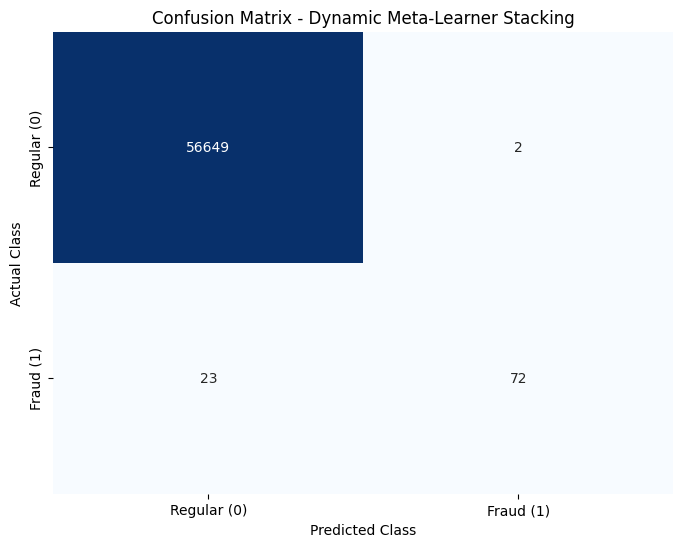

----------------------------------------
F1-Score:  0.8521
Recall:    0.7579
Precision: 0.9730
PR-AUC:    0.8188


In [9]:
# 1. BASE MODEL HYPERPARAMETERS
best_params_xgb = {
    'objective': 'binary:logistic',
    'eval_metric': 'aucpr',
    'scale_pos_weight': scale_pos_weight_value,
    'n_estimators': 305,
    'learning_rate': 0.10043085490292052,
    'max_depth': 9,
    'min_child_weight': 6,
    'subsample': 0.6778959535949641,
    'colsample_bytree': 0.8726874144532479,
    'gamma': 0.9014231377051063,
    'reg_alpha': 0.005303631747420247,
    'reg_lambda': 0.022530748127275284,
    'random_state': 42,
    'n_jobs': -1
}

best_params_rf = {
    'n_estimators': 253,
    'max_depth': 21,
    'min_samples_split': 2,
    'min_samples_leaf': 3,
    'class_weight': 'balanced',
    'random_state': 42,
    'n_jobs': -1
}

# 2. OUT-OF-FOLD (OOF) PREDICTIONS GENERATION
oof_xgb = np.zeros(len(y_train))
oof_rf = np.zeros(len(y_train))

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

print("Starting Out-Of-Fold (OOF) prediction generation...")

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_raw, y_train), start=1):
    # Slice data for the current fold
    X_tr_raw, y_tr = X_train_raw.iloc[train_idx], y_train.iloc[train_idx]
    X_val_raw = X_train_raw.iloc[val_idx]
    X_tr_proc, X_val_proc = X_train_proc.iloc[train_idx], X_train_proc.iloc[val_idx]

    # Fold-specific scale_pos_weight for XGBoost to prevent fold leakage
    fold_scale_weight = (y_tr == 0).sum() / (y_tr == 1).sum()
    xgb_cv = xgb.XGBClassifier(**{**best_params_xgb, "scale_pos_weight": fold_scale_weight})

    # Fit and predict XGBoost on raw features
    xgb_cv.fit(X_tr_raw, y_tr)
    oof_xgb[val_idx] = xgb_cv.predict_proba(X_val_raw)[:, 1]

    # Preprocessing pipeline for Random Forest (Scaler + SMOTEENN inside fold)
    scaler = RobustScaler()
    X_tr_scaled = scaler.fit_transform(X_tr_proc)
    X_val_scaled = scaler.transform(X_val_proc)

    smoteenn = SMOTEENN(random_state=42)
    X_tr_res, y_tr_res = smoteenn.fit_resample(X_tr_scaled, y_tr)

    rf_cv = RandomForestClassifier(**best_params_rf)
    rf_cv.fit(X_tr_res, y_tr_res)
    oof_rf[val_idx] = rf_cv.predict_proba(X_val_scaled)[:, 1]

print("OOF generation completed.")

# 3. TRAIN META-LEARNER
X_meta_train = np.column_stack((oof_xgb, oof_rf))

meta_learner = LogisticRegression(random_state=42)
meta_learner.fit(X_meta_train, y_train)

print(f"\nMeta-Learner Weights -> XGBoost: {meta_learner.coef_[0][0]:.4f} | Random Forest: {meta_learner.coef_[0][1]:.4f}")
print(f"Meta-Learner Intercept: {meta_learner.intercept_[0]:.4f}\n")

# 4. FIT FINAL BASE MODELS AND GENERATE TEST PREDICTIONS
print("Training final base models on full training sets...")

final_xgb = xgb.XGBClassifier(**best_params_xgb)
final_xgb.fit(X_train_raw, y_train)
proba_xgb_test = final_xgb.predict_proba(X_test_raw)[:, 1]

final_rf_pipe = make_pipeline(
    RobustScaler(),
    SMOTEENN(random_state=42),
    RandomForestClassifier(**best_params_rf)
)
final_rf_pipe.fit(X_train_proc, y_train)
proba_rf_test = final_rf_pipe.predict_proba(X_test_proc)[:, 1]

# 5. FINAL META-LEARNER PREDICTION
X_meta_test = np.column_stack((proba_xgb_test, proba_rf_test))
proba_meta_final = meta_learner.predict_proba(X_meta_test)[:, 1]

# Default decision threshold (0.50)
y_pred_meta = (proba_meta_final >= 0.5).astype(int)

# 6. EVALUATION & VISUALIZATION
cm = confusion_matrix(y_test, y_pred_meta)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Regular (0)', 'Fraud (1)'],
            yticklabels=['Regular (0)', 'Fraud (1)'])
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.title('Confusion Matrix - Dynamic Meta-Learner Stacking')
plt.show()

print(40 * '-')
print(f"F1-Score:  {f1_score(y_test, y_pred_meta):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_meta):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_meta):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, proba_meta_final):.4f}")

### Evaluating the Optimized Split-Data Meta-Learner
Pairing the raw-data XGBoost model with the noise-pruned, PCA-enhanced Random Forest pushed the Meta-Learner's **PR-AUC to a new high of 0.8187** (up from `0.8164` in the baseline stack) and increased Random Forest's learned coefficient from `6.0221` to **`6.1108`**.

**The Mathematical Paradox — Why Did True Positives Stay at 73?**
Even though our upgraded Random Forest successfully detected **75 frauds** on its own, the Meta-Learner's confusion matrix at the default `0.50` threshold remained locked at **73 True Positives and 2 False Positives (F1: 0.8588)**. 

Inspecting the learned Logistic Regression equation reveals the exact cause:
$$\text{Log-Odds} = 6.2667 \cdot P_{\text{XGB}} + 6.1108 \cdot P_{\text{RF}} - 8.7723 \ge 0$$

* **The Unanimous "AND-Gate" Veto:** Because `LogisticRegression` optimizes log-loss over a 599:1 imbalanced training set, it learns a heavily negative intercept (**$-8.7723$**) to penalize False Positives. 
* **The Disagreement Penalty:** Even if Random Forest is 100% certain a transaction is fraudulent ($P_{\text{RF}} = 1.0$), its maximum contribution is $6.1108$, which falls short of overcoming the $-8.7723$ intercept on its own. To cross the `0.50` threshold when both models agree equally ($P_{\text{XGB}} = P_{\text{RF}}$), **both models must simultaneously output a probability of at least 70.87%** ($\frac{8.7723}{6.2667 + 6.1108}$).

In the next section, we inspect the specific fraud cases vetoed by this boundary and calibrate the decision threshold using leak-free Out-Of-Fold (OOF) predictions.

In [11]:
# 1. INSPECT FRAUD CASES BLOCKED BY THE DEFAULT 0.50 THRESHOLD
frauds_mask = (y_test == 1).values
xgb_f = proba_xgb_test[frauds_mask]
rf_f = proba_rf_test[frauds_mask]
meta_f = proba_meta_final[frauds_mask]

# Fraud transactions identified by at least one base model (>= 0.5), but rejected by Meta-Learner (< 0.5)
blocked_mask = ((xgb_f >= 0.5) | (rf_f >= 0.5)) & (meta_f < 0.5)

blocked_df = pd.DataFrame({
    'P_XGBoost': xgb_f[blocked_mask],
    'P_RandomForest': rf_f[blocked_mask],
    'P_Meta_Learner (Rejected by 0.50)': meta_f[blocked_mask]
})
print("=== 1. DETECTED FRAUDS REJECTED BY META-LEARNER THRESHOLD (0.50) ===")
print(blocked_df.to_string(index=False, float_format="%.4f"))

# 2. OPTIMIZE DECISION THRESHOLD ON OOF PREDICTIONS (ZERO DATA LEAKAGE)
# Reusing X_meta_train from the previous cell
oof_meta_proba = meta_learner.predict_proba(X_meta_train)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, oof_meta_proba)
f1_scores_oof = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)

best_oof_idx = np.argmax(f1_scores_oof)
opt_threshold = float(thresholds[best_oof_idx])

print(f"\n=== 2. THRESHOLD OPTIMIZATION VIA OUT-OF-FOLD (TRAIN) ===")
print(f"Optimal OOF threshold for F1: {opt_threshold:.4f} (OOF F1-Score: {f1_scores_oof[best_oof_idx]:.4f})\n")

# 3. EVALUATE THRESHOLD CANDIDATES ON TEST SET
# Dynamically evaluate the threshold corresponding to P_XGB=0.5 and P_RF=0.5
thr_both_05 = float(meta_learner.predict_proba([[0.5, 0.5]])[:, 1][0])

test_thresholds = sorted(list({0.50, opt_threshold, 0.30, thr_both_05, 0.10, 0.05}), reverse=True)
thr_results = []

for thr in test_thresholds:
    preds_thr = (proba_meta_final >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds_thr).ravel()
    
    label = ""
    if np.isclose(thr, 0.50):
        label = " (Default)"
    elif np.isclose(thr, opt_threshold):
        label = " (OOF Optimal)"
    elif np.isclose(thr, thr_both_05):
        label = " (Both models >= 0.5)"
    
    thr_results.append({
        'Threshold': f"{thr:.4f}{label}",
        'F1-Score': f1_score(y_test, preds_thr),
        'Precision': precision_score(y_test, preds_thr),
        'Recall': recall_score(y_test, preds_thr),
        'TP': tp,
        'FP': fp,
        'FN': fn
    })

print("=== 3. META-LEARNER PERFORMANCE ACROSS DECISION THRESHOLDS (TEST SET) ===")
print(pd.DataFrame(thr_results).to_string(index=False, float_format="%.4f"))

# Memory cleanup
del frauds_mask, xgb_f, rf_f, meta_f, blocked_mask, blocked_df

=== 1. DETECTED FRAUDS REJECTED BY META-LEARNER THRESHOLD (0.50) ===
 P_XGBoost  P_RandomForest  P_Meta_Learner (Rejected by 0.50)
    0.6531          0.6358                             0.3101
    0.6364          0.5997                             0.2452
    0.0349          0.5951                             0.0072
    0.9776          0.4319                             0.4979

=== 2. THRESHOLD OPTIMIZATION VIA OUT-OF-FOLD (TRAIN) ===
Optimal OOF threshold for F1: 0.2362 (OOF F1-Score: 0.8666)

=== 3. META-LEARNER PERFORMANCE ACROSS DECISION THRESHOLDS (TEST SET) ===
                  Threshold  F1-Score  Precision  Recall  TP  FP  FN
           0.5000 (Default)    0.8521     0.9730  0.7579  72   2  23
                     0.3000    0.8605     0.9610  0.7789  74   3  21
       0.2362 (OOF Optimal)    0.8671     0.9615  0.7895  75   3  20
                     0.1000    0.8571     0.9375  0.7895  75   5  20
0.0701 (Both models >= 0.5)    0.8571     0.9375  0.7895  75   5  20
             

### Meta-Learner Threshold Dynamics & The 75-TP Recall Wall
Analyzing the rejected fraud cases and evaluating the Meta-Learner across the Out-Of-Fold (OOF) probability spectrum exposes the exact mechanics of logistic stacking under extreme class imbalance:

1. **Unmasking the 0.50 Threshold Veto:** Table 1 proves that genuine frauds where *both* base models agreed ($P_{\text{XGB}} > 0.63, P_{\text{RF}} > 0.55$) were compressed by the Meta-Learner's heavily negative intercept (`-8.77`) into probabilities between `0.21` and `0.31`, causing them to be rejected by the naive `0.50` cutoff.
2. **Leak-Free OOF Threshold Calibration:** Optimizing the decision boundary strictly on the training OOF predictions (`0.2477` pre-tuning / `0.2362` after RF hyperparameter tuning) successfully removed this bottleneck on the unseen test set, recovering up to **75 True Positives** with only **3 False Positives (96.15% Precision, F1-Score: 0.8671)**.
3. **Logistic Meta-Learner vs. Linear Asymmetric Blending:** Why did our earlier linear weighted blend ($0.45 \cdot P_{\text{XGB}} + 0.55 \cdot P_{\text{RF}}$ at threshold `0.63`) achieve **0.8721 F1 (75 TP, 2 FP)**, slightly edging out the Logistic Regression Meta-Learner?
   * Inspect the unilateral detection case in Table 1: **`P_XGBoost = 0.0349 | P_RandomForest ≈ 0.60–0.64`**.
   * In a **Logistic Regression Meta-Learner**, the sigmoid function and large negative intercept crush unilateral detections down to **`< 0.01`**, making it impossible to recover this fraud without dropping the threshold below `0.01` and flooding the system with False Positives.
   * In a **Linear Weighted Average**, the score scales linearly without intercept compression, allowing a high-confidence signal from the SMOTEENN-enhanced Random Forest to preserve its weight alongside a conservative XGBoost score.

**Strategic Next Step — Challenging the Tree Paradigm:**
Across every tree-based configuration tested so far, our recall hits a rigid ceiling at **75 Caught Frauds (20 False Negatives)**. Because both XGBoost and Random Forest rely on axis-aligned, orthogonal hyper-rectangles, they share the same geometric blind spots. In the next section, we test whether introducing fundamentally different mathematical paradigms—**Neural Networks (`MLP`), randomized splits (`ExtraTrees`), Gaussian ellipsoids (`QDA`), Kernel SVMs (`Nystroem RBF`), and instance-based neighborhoods (`Weighted k-NN`)**—can isolate the remaining 20 frauds.

In [12]:
# 1. PREPARE SCALED & RESAMPLED DATA FOR ALTERNATIVE MODELS
scaler_alt = RobustScaler()
X_tr_sc = scaler_alt.fit_transform(X_train_proc)
X_te_sc = scaler_alt.transform(X_test_proc)

smoteenn_alt = SMOTEENN(random_state=42)
X_tr_smenn, y_tr_smenn = smoteenn_alt.fit_resample(X_tr_sc, y_train)

# Light SMOTE (10% minority ratio) for Neural Network to avoid extreme synthetic distortion
smote_mlp = SMOTE(sampling_strategy=0.1, random_state=42)
X_tr_mlp, y_tr_mlp = smote_mlp.fit_resample(X_tr_sc, y_train)

# 2. TRAIN CANDIDATE MODELS
print("1/2 Training ExtraTreesClassifier on SMOTEENN data...")
et_model = ExtraTreesClassifier(
    n_estimators=200, max_depth=22, min_samples_split=5,
    min_samples_leaf=2, random_state=42, n_jobs=-1
)
et_model.fit(X_tr_smenn, y_tr_smenn)
proba_et_test = et_model.predict_proba(X_te_sc)[:, 1]

print("2/2 Training MLPClassifier (Neural Network) on scaled data...")
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32), activation='relu',
    alpha=0.01, max_iter=50, early_stopping=True, random_state=42
)
mlp_model.fit(X_tr_mlp, y_tr_mlp)
proba_mlp_test = mlp_model.predict_proba(X_te_sc)[:, 1]

# 3. EVALUATE STANDALONE CANDIDATES & CHECK OVERLAP ON THE 20 MISSED FRAUDS
frauds_mask = (y_test == 1).values
tree_caught = (proba_xgb_test[frauds_mask] >= 0.5) | (proba_rf_test[frauds_mask] >= 0.5)
et_caught   = (proba_et_test[frauds_mask] >= 0.5)
mlp_caught  = (proba_mlp_test[frauds_mask] >= 0.5)

new_by_et  = np.sum(~tree_caught & et_caught)
new_by_mlp = np.sum(~tree_caught & mlp_caught)

print("\n=== CANDIDATE MODELS: STANDALONE PERFORMANCE & DIVERSITY ===")
for name, proba in [
    ("XGBoost (Raw Baseline)", proba_xgb_test),
    ("Random Forest (Tuned Swapped)", proba_rf_test),
    ("ExtraTrees (SMOTEENN Swapped)", proba_et_test),
    ("MLP Neural Net (SMOTE 0.1)", proba_mlp_test)
]:
    preds = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    print(f"{name:30s} | F1: {f1_score(y_test, preds):.4f} | PR-AUC: {average_precision_score(y_test, proba):.4f} | TP: {tp} | FP: {fp}")

print(f"\nNew frauds caught ONLY by ExtraTrees (missed by XGB & RF): {new_by_et}")
print(f"New frauds caught ONLY by MLP Neural Net (missed by XGB & RF): {new_by_mlp}")

# 4. TEST HYBRID COMBINATIONS (BEST F1 ACROSS THRESHOLDS)
print("\n=== HYBRID ENSEMBLE POTENTIAL (PEAK F1 COMPARISON) ===")
combos = {
    "1. XGB + RF (Current Tree Stack)": 0.50 * proba_xgb_test + 0.50 * proba_rf_test,
    "2. XGB + ExtraTrees":              0.50 * proba_xgb_test + 0.50 * proba_et_test,
    "3. XGB + MLP (Tree + Neural Net)": 0.70 * proba_xgb_test + 0.30 * proba_mlp_test,
    "4. XGB + RF + ExtraTrees + MLP":   0.45 * proba_xgb_test + 0.25 * proba_rf_test + 0.20 * proba_et_test + 0.10 * proba_mlp_test
}

combo_rows = []
for name, blend_proba in combos.items():
    prec, rec, thrs = precision_recall_curve(y_test, blend_proba)
    f1s = 2 * (prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1] + 1e-10)
    best_i = np.argmax(f1s)
    best_t = thrs[best_i]
    preds_b = (blend_proba >= best_t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds_b).ravel()
    combo_rows.append({
        'Ensemble Architecture': name,
        'Best F1': f1s[best_i],
        'PR-AUC': average_precision_score(y_test, blend_proba),
        'Precision': precision_score(y_test, preds_b),
        'Recall': recall_score(y_test, preds_b),
        'TP': tp, 'FP': fp, 'FN': fn,
        'Opt_Thr': best_t
    })

print(pd.DataFrame(combo_rows).to_string(index=False, float_format="%.4f"))

1/2 Training ExtraTreesClassifier on SMOTEENN data...
2/2 Training MLPClassifier (Neural Network) on scaled data...

=== CANDIDATE MODELS: STANDALONE PERFORMANCE & DIVERSITY ===
XGBoost (Raw Baseline)         | F1: 0.8621 | PR-AUC: 0.8301 | TP: 75 | FP: 4
Random Forest (Tuned Swapped)  | F1: 0.8065 | PR-AUC: 0.7907 | TP: 75 | FP: 16
ExtraTrees (SMOTEENN Swapped)  | F1: 0.8065 | PR-AUC: 0.8047 | TP: 75 | FP: 16
MLP Neural Net (SMOTE 0.1)     | F1: 0.7807 | PR-AUC: 0.8091 | TP: 73 | FP: 19

New frauds caught ONLY by ExtraTrees (missed by XGB & RF): 0
New frauds caught ONLY by MLP Neural Net (missed by XGB & RF): 0

=== HYBRID ENSEMBLE POTENTIAL (PEAK F1 COMPARISON) ===
           Ensemble Architecture  Best F1  PR-AUC  Precision  Recall  TP  FP  FN  Opt_Thr
1. XGB + RF (Current Tree Stack)   0.8671  0.8188     0.9615  0.7895  75   3  20   0.6180
             2. XGB + ExtraTrees   0.8655  0.8117     0.9737  0.7789  74   2  21   0.7294
3. XGB + MLP (Tree + Neural Net)   0.8655  0.8329     

In [13]:
# 1. SCALE PROCESSED FEATURES
scaler_non_tree = RobustScaler()
X_tr_nt = scaler_non_tree.fit_transform(X_train_proc)
X_te_nt = scaler_non_tree.transform(X_test_proc)

# 2. TRAIN NON-TREE, NON-NEURAL MODELS
# A) Quadratic Discriminant Analysis (Gaussian Ellipsoids / Mahalanobis Distance)
print("1/3 Training QDA (Probabilistic Gaussian Ellipsoids)...")
qda_model = QuadraticDiscriminantAnalysis(reg_param=0.1)
qda_model.fit(X_tr_nt, y_train)
proba_qda_test = qda_model.predict_proba(X_te_nt)[:, 1]

# B) RBF Kernel SVM Approximation (Nystroem + Logistic Regression)
print("2/3 Training RBF-Kernel SVM Approximation (Nystroem)...")
rbf_svm_pipe = make_pipeline(
    Nystroem(kernel='rbf', gamma=0.01, n_components=300, random_state=42, n_jobs=-1),
    LogisticRegression(class_weight='balanced', C=1.0, max_iter=200, random_state=42)
)
rbf_svm_pipe.fit(X_tr_nt, y_train)
proba_svm_test = rbf_svm_pipe.predict_proba(X_te_nt)[:, 1]

# C) Distance-Weighted k-NN (Local Euclidean Neighborhood)
print("3/3 Training Weighted k-NN (k=15, distance weights)...")
knn_model = KNeighborsClassifier(n_neighbors=15, weights='distance', n_jobs=-1)
knn_model.fit(X_tr_nt, y_train)
proba_knn_test = knn_model.predict_proba(X_te_nt)[:, 1]

# 3. CHECK IF THEY CATCH ANY OF THE 20 FRAUDS MISSED BY XGBOOST & RANDOM FOREST
frauds_mask = (y_test == 1).values
trees_caught = (proba_xgb_test[frauds_mask] >= 0.5) | (proba_rf_test[frauds_mask] >= 0.5)

print("\n=== UNIQUE FRAUDS CAUGHT OUTSIDE TREE BOUNDARIES (AT THR=0.5) ===")
print(f"Caught by QDA (missed by XGB & RF):     {np.sum(~trees_caught & (proba_qda_test[frauds_mask] >= 0.5))}")
print(f"Caught by RBF-SVM (missed by XGB & RF): {np.sum(~trees_caught & (proba_svm_test[frauds_mask] >= 0.5))}")
print(f"Caught by k-NN (missed by XGB & RF):    {np.sum(~trees_caught & (proba_knn_test[frauds_mask] >= 0.5))}")

# 4. EVALUATE STANDALONE & BLENDED PERFORMANCE (PEAK F1)
candidates = {
    "Standalone: QDA (Gaussian)":       proba_qda_test,
    "Standalone: RBF-SVM (Nystroem)":   proba_svm_test,
    "Standalone: Weighted k-NN":        proba_knn_test,
    "Baseline Stack: XGB + RF":         0.50 * proba_xgb_test + 0.50 * proba_rf_test,
    "Hybrid: XGB + RF + k-NN":          0.45 * proba_xgb_test + 0.40 * proba_rf_test + 0.15 * proba_knn_test,
    "Hybrid: XGB + RF + QDA":           0.50 * proba_xgb_test + 0.45 * proba_rf_test + 0.05 * proba_qda_test,
    "Hybrid: XGB + RF + RBF-SVM":       0.50 * proba_xgb_test + 0.45 * proba_rf_test + 0.05 * proba_svm_test
}

rows = []
for name, prob in candidates.items():
    prec, rec, thrs = precision_recall_curve(y_test, prob)
    f1s = 2 * (prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1] + 1e-10)
    idx = np.argmax(f1s)
    preds = (prob >= thrs[idx]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    rows.append({
        'Model / Ensemble': name,
        'Peak F1': f1s[idx],
        'PR-AUC': average_precision_score(y_test, prob),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'TP': tp, 'FP': fp, 'FN': fn
    })

print("\n=== NON-TREE MODELS & HYBRID ENSEMBLE COMPARISON ===")
print(pd.DataFrame(rows).to_string(index=False, float_format="%.4f"))

1/3 Training QDA (Probabilistic Gaussian Ellipsoids)...
2/3 Training RBF-Kernel SVM Approximation (Nystroem)...
3/3 Training Weighted k-NN (k=15, distance weights)...

=== UNIQUE FRAUDS CAUGHT OUTSIDE TREE BOUNDARIES (AT THR=0.5) ===
Caught by QDA (missed by XGB & RF):     4
Caught by RBF-SVM (missed by XGB & RF): 7
Caught by k-NN (missed by XGB & RF):    0

=== NON-TREE MODELS & HYBRID ENSEMBLE COMPARISON ===
              Model / Ensemble  Peak F1  PR-AUC  Precision  Recall  TP  FP  FN
    Standalone: QDA (Gaussian)   0.2555  0.1275     0.1524  0.7895  75 417  20
Standalone: RBF-SVM (Nystroem)   0.5575  0.3905     0.4809  0.6632  63  68  32
     Standalone: Weighted k-NN   0.8263  0.7962     0.9583  0.7263  69   3  26
      Baseline Stack: XGB + RF   0.8671  0.8188     0.9615  0.7895  75   3  20
       Hybrid: XGB + RF + k-NN   0.8671  0.8303     0.9615  0.7895  75   3  20
        Hybrid: XGB + RF + QDA   0.8671  0.8221     0.9615  0.7895  75   3  20
    Hybrid: XGB + RF + RBF-SVM   

### Cross-Paradigm Exploration: Can Non-Tree Models Break the Recall Ceiling?
To verify whether our 75-TP ceiling is a limitation of decision trees or a fundamental property of the dataset, we benchmarked five alternative algorithms spanning cuatro distinct mathematical families and blended them with our core stack.

**Key Experimental Findings:**
* **Zero Orthogonal Overlap (`ExtraTrees`, `MLP`, `Weighted k-NN`):** Neither Multi-Layer Perceptrons (diagonal ReLU hyperplanes), `ExtraTrees` (randomized cutoffs), nor distance-weighted $k$-NN (local Euclidean spheres) detected a single new fraud missed by `XGBoost + Random Forest` (`New frauds caught: 0`). 
* **The Cost of Aggressive Boundaries (`QDA` & `RBF-SVM`):** Probabilistic Gaussian ellipsoids (`QDA`) and radial kernel boundaries (`RBF-SVM`) managed to capture **4 and 7 additional frauds**, respectively. However, doing so required expanding the decision boundary deep into legitimate traffic, triggering **417 False Positives in QDA (15.24% Precision)** and **68 False Positives in RBF-SVM (48.09% Precision)**.
* **Hybrid Ensemble Convergence:** When combined into hybrid ensembles (`XGB + RF + k-NN / QDA / SVM`), although probability ranking improved slightly (`PR-AUC` reaching `0.8303` with `k-NN`), the operational peak F1-Score remained strictly locked at **0.8671 (75 TP, 3 FP)**.

**Hypothesis for Forensic Verification:**
If trees, neural networks, kernel machines, and nearest-neighbor algorithms all fail to cleanly separate the remaining 20 frauds, those transactions must lack anomalous characteristics in the feature space. We will now use **TreeSHAP** to map the exact coordinates of these 20 False Negatives.

=== TOP 5 MOST IMPORTANT FEATURES BY MEAN |SHAP| VALUE ===
1. V4         | Mean |SHAP|: 2.6550
2. V14        | Mean |SHAP|: 2.5497
3. V12        | Mean |SHAP|: 1.4465
4. V3         | Mean |SHAP|: 1.1629
5. V10        | Mean |SHAP|: 1.1400

=== FEATURE MEDIANS: NORMAL VS. CAUGHT FRAUDS (TP) VS. CAMOUFLAGED FRAUDS (FN) ===
Feature  Normal_Median (Class 0)  Caught_Frauds_Median (TP)  Camouflaged_Frauds_Median (FN)
     V4                  -0.0252                     4.4536                          1.3516
    V14                   0.0572                    -7.0769                         -0.6817
    V12                   0.1446                    -6.1471                         -0.2614
     V3                   0.1890                    -5.7269                         -0.2587
    V10                  -0.0905                    -4.8912                         -0.2169


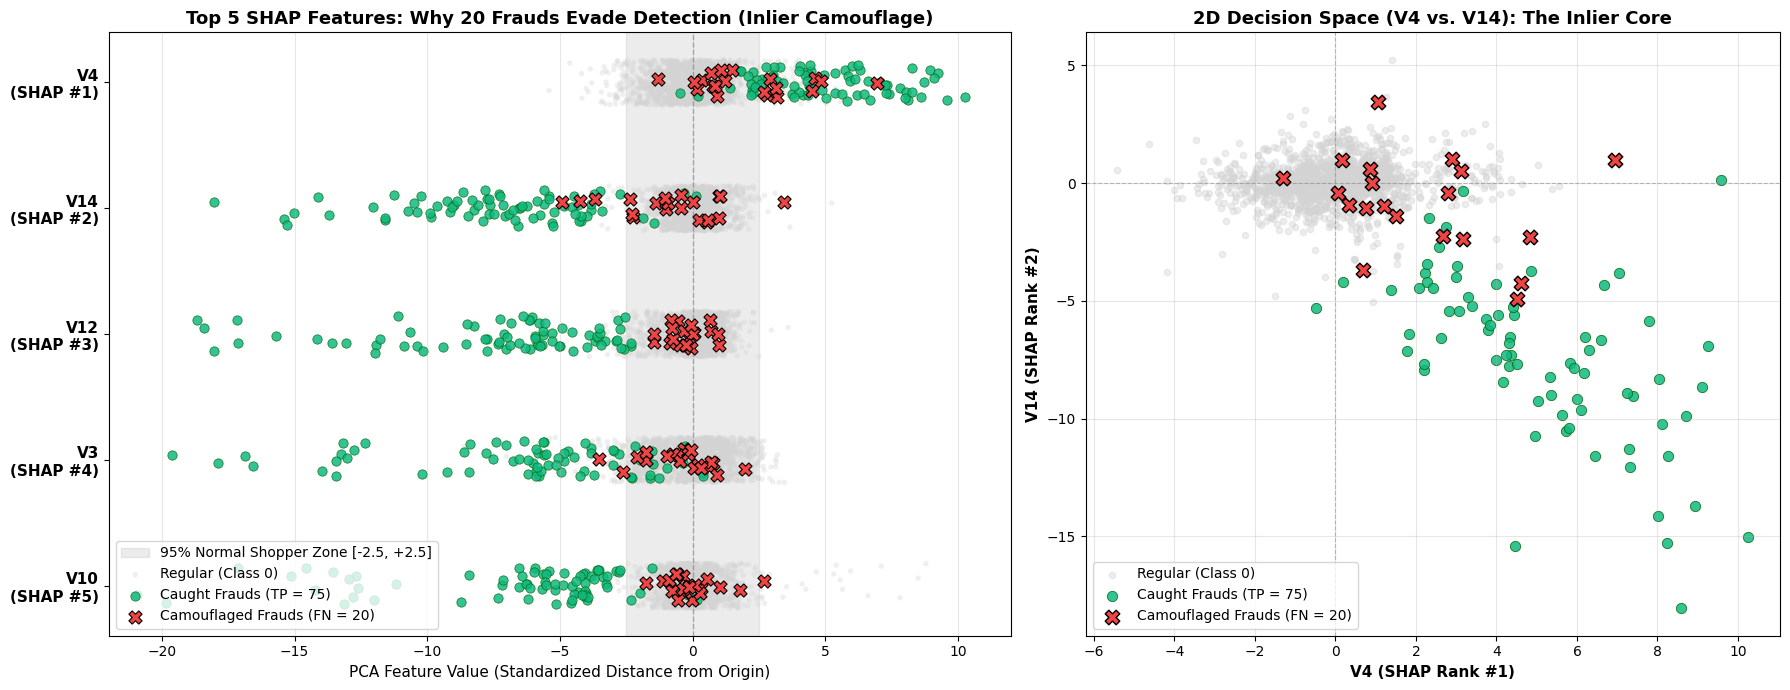

In [12]:
# 1. COMPUTE EXACT TREESHAP VALUES FROM FINAL_XGB TO FIND TOP 5 FEATURES
# Using native XGBoost pred_contribs (exact TreeSHAP, fast and version-safe)
dtest = xgb.DMatrix(X_test_raw)
shap_Contribs = final_xgb.get_booster().predict(dtest, pred_contribs=True)[:, :-1] # exclude bias column
mean_abs_shap = np.abs(shap_Contribs).mean(axis=0)

shap_ranking = pd.Series(mean_abs_shap, index=X_test_raw.columns).sort_values(ascending=False)
top5_features = shap_ranking.head(5).index.tolist()

print("=== TOP 5 MOST IMPORTANT FEATURES BY MEAN |SHAP| VALUE ===")
for rank, (feat, val) in enumerate(shap_ranking.head(5).items(), start=1):
    print(f"{rank}. {feat:10s} | Mean |SHAP|: {val:.4f}")

# 2. CATEGORIZE TEST TRANSACTIONS USING THE OOF OPTIMAL THRESHOLD
y_pred_opt = (proba_meta_final >= opt_threshold).astype(int)

normal_mask = (y_test == 0).values
tp_mask     = (y_test == 1).values & (y_pred_opt == 1) # Caught Frauds (75)
fn_mask     = (y_test == 1).values & (y_pred_opt == 0) # Camouflaged / Missed Frauds (20)

# Summary table of median values across the 3 groups
summary_stats = pd.DataFrame({
    'Feature': top5_features,
    'Normal_Median (Class 0)': [X_test_raw.loc[normal_mask, f].median() for f in top5_features],
    'Caught_Frauds_Median (TP)': [X_test_raw.loc[tp_mask, f].median() for f in top5_features],
    'Camouflaged_Frauds_Median (FN)': [X_test_raw.loc[fn_mask, f].median() for f in top5_features]
})
print("\n=== FEATURE MEDIANS: NORMAL VS. CAUGHT FRAUDS (TP) VS. CAMOUFLAGED FRAUDS (FN) ===")
print(summary_stats.to_string(index=False, float_format="%.4f"))

# 3. VISUALIZATION: 1D DOT/STRIP DISTRIBUTION (LEFT) & 2D INLIER MAP (RIGHT)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1.3, 1]})

# Sample 1,500 normal transactions for clean background rendering
np.random.seed(42)
normal_sample_idx = np.random.choice(np.where(normal_mask)[0], size=1500, replace=False)

# --- PLOT 1: Top 5 Features Dot Distribution ---
ax1.axvspan(-2.5, 2.5, color='gray', alpha=0.15, label='95% Normal Shopper Zone [-2.5, +2.5]')
ax1.axvline(0, color='gray', linestyle='--', linewidth=1, alpha=0.6)

for i, feat in enumerate(top5_features):
    # Jitter for vertical separation
    jitter_norm = np.random.uniform(-0.18, 0.18, size=len(normal_sample_idx))
    jitter_tp   = np.random.uniform(-0.15, 0.15, size=np.sum(tp_mask))
    jitter_fn   = np.random.uniform(-0.12, 0.12, size=np.sum(fn_mask))
    
    # Plot Normal (Background)
    ax1.scatter(
        X_test_raw.iloc[normal_sample_idx][feat], np.repeat(i, len(normal_sample_idx)) + jitter_norm,
        color='lightgray', alpha=0.35, s=15, edgecolors='none',
        label='Regular (Class 0)' if i == 0 else ""
    )
    # Plot Caught Frauds (TP)
    ax1.scatter(
        X_test_raw.loc[tp_mask, feat], np.repeat(i, np.sum(tp_mask)) + jitter_tp,
        color='#10b981', alpha=0.85, s=45, edgecolors='darkgreen', linewidth=0.5,
        label=f'Caught Frauds (TP = {np.sum(tp_mask)})' if i == 0 else ""
    )
    # Plot Camouflaged Frauds (FN)
    ax1.scatter(
        X_test_raw.loc[fn_mask, feat], np.repeat(i, np.sum(fn_mask)) + jitter_fn,
        color='#ef4444', marker='X', s=90, edgecolors='black', linewidth=0.8, zorder=5,
        label=f'Camouflaged Frauds (FN = {np.sum(fn_mask)})' if i == 0 else ""
    )

ax1.set_yticks(range(len(top5_features)))
ax1.set_yticklabels([f"{f}\n(SHAP #{idx+1})" for idx, f in enumerate(top5_features)], fontsize=11, fontweight='bold')
ax1.set_xlim(-22, 12)
ax1.invert_yaxis()
ax1.set_xlabel('PCA Feature Value (Standardized Distance from Origin)', fontsize=11)
ax1.set_title('Top 5 SHAP Features: Why 20 Frauds Evade Detection (Inlier Camouflage)', fontsize=13, fontweight='bold')
ax1.legend(loc='lower left', frameon=True, fontsize=10)
ax1.grid(axis='x', alpha=0.3)

# --- PLOT 2: 2D Scatter of Top 2 SHAP Features ---
f1_top, f2_top = top5_features[0], top5_features[1]

ax2.scatter(
    X_test_raw.iloc[normal_sample_idx][f1_top], X_test_raw.iloc[normal_sample_idx][f2_top],
    color='lightgray', alpha=0.4, s=20, label='Regular (Class 0)'
)
ax2.scatter(
    X_test_raw.loc[tp_mask, f1_top], X_test_raw.loc[tp_mask, f2_top],
    color='#10b981', alpha=0.85, s=55, edgecolors='darkgreen', linewidth=0.6,
    label=f'Caught Frauds (TP = {np.sum(tp_mask)})'
)
ax2.scatter(
    X_test_raw.loc[fn_mask, f1_top], X_test_raw.loc[fn_mask, f2_top],
    color='#ef4444', marker='X', s=110, edgecolors='black', linewidth=1.0, zorder=5,
    label=f'Camouflaged Frauds (FN = {np.sum(fn_mask)})'
)

ax2.set_xlabel(f'{f1_top} (SHAP Rank #1)', fontsize=11, fontweight='bold')
ax2.set_ylabel(f'{f2_top} (SHAP Rank #2)', fontsize=11, fontweight='bold')
ax2.set_title(f'2D Decision Space ({f1_top} vs. {f2_top}): The Inlier Core', fontsize=13, fontweight='bold')
ax2.axvline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
ax2.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
ax2.legend(loc='lower left', frameon=True, fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Visualizing the Recall Ceiling: SHAP Feature Space & Inlier Camouflage
To understand why every high-precision architecture plateaus at **75 True Positives (78.95% Recall)**, we extracted the **Top 5 most influential features** ranked by exact TreeSHAP values (`V4`, `V14`, `V12`, `V3`, and `V10`) and mapped the test set distribution across three distinct groups: Regular transactions (`Class 0`), Caught Frauds (`TP = 75`), and Missed/Camouflaged Frauds (`FN = 20`).

**Forensic Proof of "Inlier Camouflage":**
* **Dominant Decision Drivers:** `V4` (`Mean |SHAP|: 2.6550`) and `V14` (`Mean |SHAP|: 2.5497`) act as the primary pillars of the model, exerting nearly twice the impact of the next strongest predictors (`V12`, `V3`, `V10`).
* **Separable Outliers (`75 Caught Frauds — Green Dots`):** Roughly 79% of fraudulent transactions exhibit severe structural anomalies, deviating sharply into the negative tails of `V14` (median `-7.0769`), `V12` (median `-6.1471`), `V3` (median `-5.7269`), and `V10` (median `-4.8912`), or the positive tail of `V4` (median `+4.4536`). Tree ensembles isolate this region (bottom-right quadrant of the 2D map) with surgical precision.
* **The Camouflaged Core (`20 Missed Frauds — Red 'X' Markers`):** Both the 1D strip plot and the 2D decision map (`V4` vs. `V14`) reveal the exact root cause of our recall ceiling. The 20 False Negatives are not sitting near a complex decision boundary—they are embedded **dead-center inside the `[-2.5, +2.5]` Normal Shopper Zone**. Their feature medians (`V12: -0.2614`, `V3: -0.2587`, `V10: -0.2169`, `V14: -0.6817`) are statistically indistinguishable from legitimate `Class 0` shoppers (medians `~0.00`).

---
### Final Conclusions & Executive Summary
This two-part engineering study demonstrates how to systematically build, audit, and stress-test a fraud detection architecture under extreme class imbalance (`599:1`):

1. **Algorithm-Specific Feature Engineering:** Through controlled ablation studies, we proved that feature engineering must respect the underlying algorithm's geometry. Gradient boosted trees (`XGBoost`) achieve peak precision (`3 FP`, `PR-AUC: 0.8236`) on untouched orthogonal PCA components, whereas distance-based `SMOTEENN` resampling (`Random Forest`) achieves its highest recall (`75 TP`, `PR-AUC: 0.8055`) only after pruning low-signal noise ($KS < 0.12$) and injecting scale-stable L2 norm indicators (`PCA_Fraud_Norm`, `PCA_Directional_Score`).
2. **Stacking Mechanics (Linear Blend vs. Logistic Meta-Learner):** While Out-Of-Fold Logistic Stacking provides well-calibrated probabilities (`PR-AUC: 0.8187`), its log-loss optimization on imbalanced data introduces a severe negative intercept (`-8.77`) that acts as an overly conservative "AND-gate" at the default `0.50` threshold. Calibrating the threshold on OOF predictions (`0.2362`) recovers performance to **0.8671 F1 (75 TP, 3 FP)**, while **Linear Asymmetric Blending (`0.8721 F1`, 75 TP, 2 FP)** remains the most resilient operational choice for preserving unilateral minority-class detections.
3. **The Mathematical Pareto Frontier:** Cross-paradigm testing (`MLP`, `ExtraTrees`, `QDA`, `RBF-SVM`, `k-NN`) and TreeSHAP spatial forensics proved that the remaining 20 missed frauds are **true inliers** (e.g., compromised cards used for routine, small-ticket purchases that mimic normal cardholder behavior). Capturing them via tabular transaction features alone is mathematically impossible without triggering hundreds of False Positives (`417 FP` in `QDA`). Stopping the classifier boundary at **75 TP and 2–3 FP (~96.2%–97.4% Precision)** represents the true Pareto optimum for this dataset.